<a href="https://colab.research.google.com/github/oumaklaus/Deathon-ML-Internship/blob/main/California_Housing_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/oumaklaus/Deathon-ML-Internship/blob/main/California_Housing_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## 1. Data Loading


In [1]:
import urllib.request

base_url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
housing_file = "housing.csv"
urllib.request.urlretrieve(base_url, housing_file)


('housing.csv', <http.client.HTTPMessage at 0x7f2c7a669040>)

In [2]:
!ls


California_Housing_Pipeline.ipynb   README.md
housing.csv			    Sentiment_Reviews_Pipeline.ipynb
Iris_classification_pipeline.ipynb  Telco_Churn_Pipeline.ipynb


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score)

RANDOM_STATE = 42
sns.set_theme(style = "whitegrid")


In [4]:
df = pd.read_csv("housing.csv")


# 2. EDA


In [5]:
df.shape


(20640, 10)

In [6]:
df.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [7]:
df.tail()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [8]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [9]:
df.describe()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [10]:
df.isnull().sum()


longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [11]:
df['ocean_proximity'].value_counts()


ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

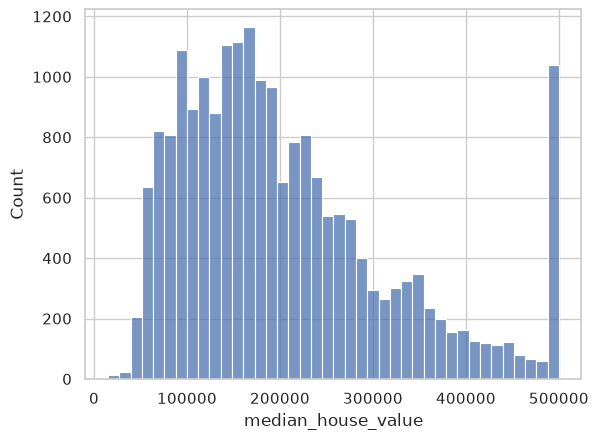

In [12]:
sns.histplot(data=df, x = "median_house_value", bins=40)
plt.show()


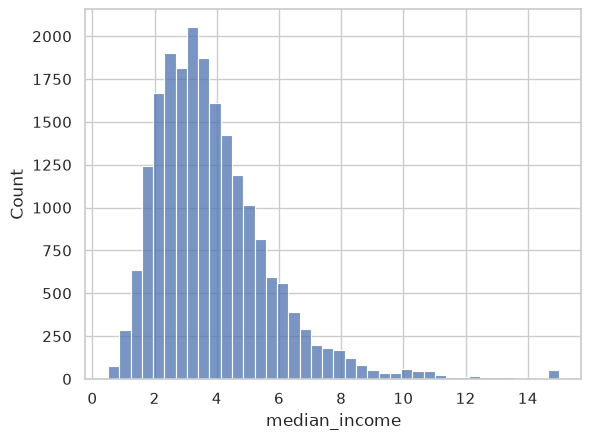

In [13]:
sns.histplot(data=df, x = "median_income", bins=40)
plt.show()


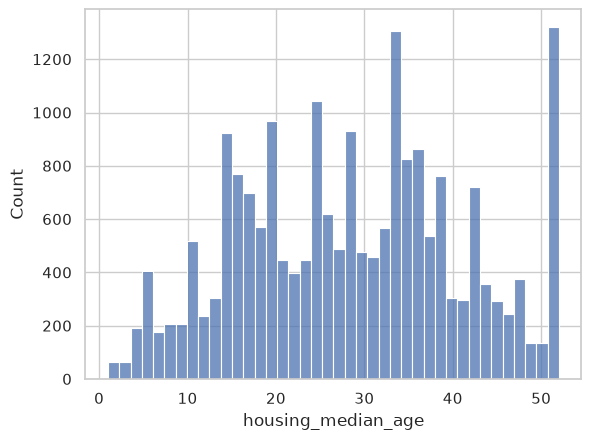

In [14]:
sns.histplot(data=df, x = "housing_median_age", bins=40)
plt.show()


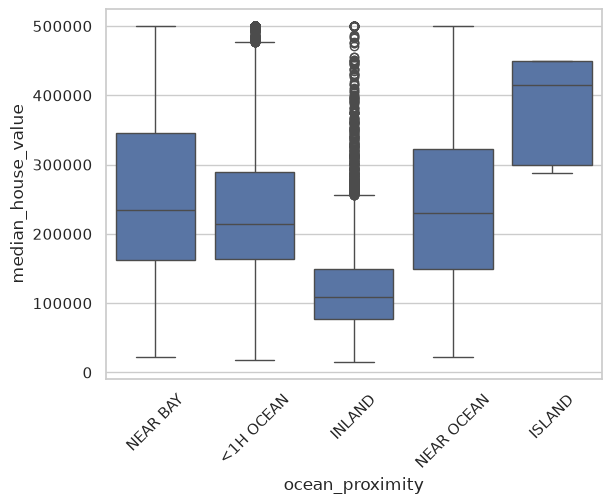

In [15]:
sns.boxplot(data=df, x = "ocean_proximity", y = "median_house_value")
plt.xticks(rotation=45)
plt.show()


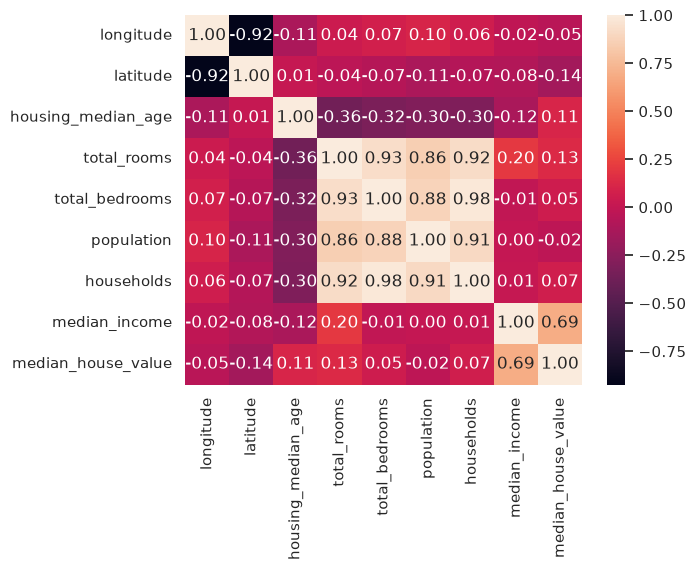

In [16]:
# only numeric columns -> drop the categorical one for a numeric correlation matrix
sns.heatmap(df.drop(columns='ocean_proximity').corr(), annot=True, fmt=".2f")
plt.show()


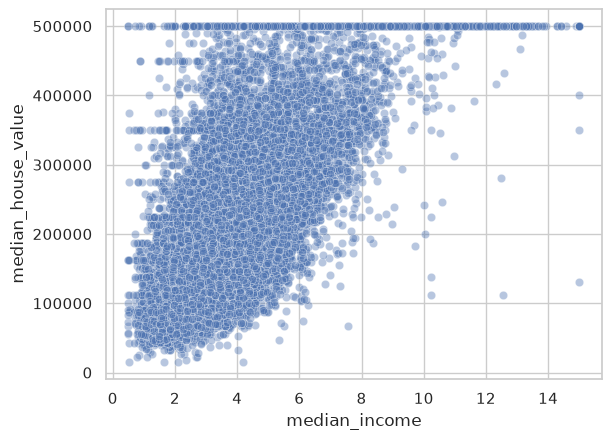

In [17]:
sns.scatterplot(data=df, x = "median_income", y = "median_house_value", alpha=0.4)
plt.show()


## 3. Handling Missing Values


In [18]:
# total_bedrooms has some missing values -> fill with the median
df = df.copy()
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())
print(df.isnull().sum().sum(), "missing values remain")


0 missing values remain


## 4. Dataset Splitting


In [19]:
X = df.drop(columns = "median_house_value")
y = df["median_house_value"]


In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = RANDOM_STATE)


In [21]:
print("X Train: ", X_train.shape)


X Train:  (16512, 9)


In [22]:
print("X Test: ", X_test.shape)


X Test:  (4128, 9)


## 5. Encoding & Feature Scaling


In [23]:
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = ["ocean_proximity"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])


In [24]:
X_train_s = preprocessor.fit_transform(X_train)
X_test_s = preprocessor.transform(X_test)


## 6. Model Training


In [25]:
lin_reg = LinearRegression()
tree = DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE)

lin_reg.fit(X_train_s, y_train)
tree.fit(X_train_s, y_train)

pred_lin = lin_reg.predict(X_test_s)
pred_tree = tree.predict(X_test_s)


## 7. Model Evaluation


In [26]:
def report(name, y_true, y_pred):
    print(name)
    print(f"  MAE : {mean_absolute_error(y_true, y_pred):,.2f}")
    print(f"  RMSE: {root_mean_squared_error(y_true, y_pred):,.2f}")
    print(f"  R^2 : {r2_score(y_true, y_pred):.4f}")
    print()

report("Linear Regression", y_test, pred_lin)
report("Decision Tree", y_test, pred_tree)


Linear Regression
  MAE : 50,670.74
  RMSE: 70,060.52
  R^2 : 0.6254

Decision Tree
  MAE : 50,295.92
  RMSE: 71,452.88
  R^2 : 0.6104



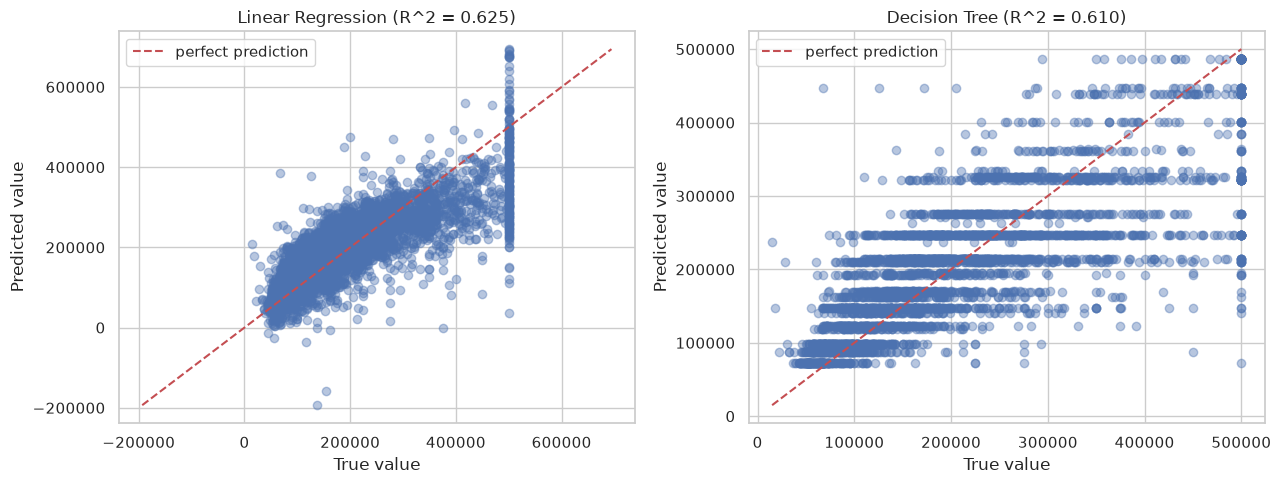

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, y_pred) in zip(axes, [("Linear Regression", pred_lin), ("Decision Tree", pred_tree)]):
    ax.scatter(y_test, y_pred, alpha=0.4)
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', label="perfect prediction")
    ax.set_xlabel("True value")
    ax.set_ylabel("Predicted value")
    ax.set_title(f"{name} (R^2 = {r2_score(y_test, y_pred):.3f})")
    ax.legend()
plt.tight_layout()
plt.show()


## 8. Feature Importance (Decision Tree)


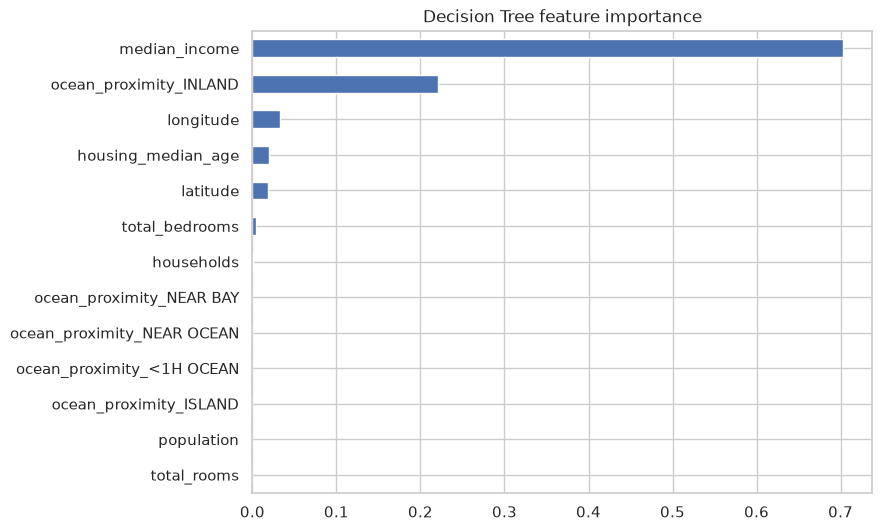

In [28]:
feature_names = num_cols + list(preprocessor.named_transformers_['cat'].get_feature_names_out(['ocean_proximity']))
imp = pd.Series(tree.feature_importances_, index=feature_names).sort_values()
imp.plot(kind="barh", title="Decision Tree feature importance", figsize=(8, 6))
plt.show()


## 9. Cross-Validation


In [29]:
cv_scores = cross_val_score(tree, X_train_s, y_train, cv=5, scoring="r2")
print(f"Decision Tree CV R^2: {cv_scores}")
print(f"Mean CV R^2         : {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")


Decision Tree CV R^2: [0.63589042 0.61719422 0.62499307 0.64068655 0.62482654]
Mean CV R^2         : 0.6287 (+/- 0.0084)
